# 7. SVC (rbf)

The same margin idea with an RBF kernel `K(a, b) = exp(-gamma |a - b|^2)`: the boundary can curve around
groups of borrowers. Solved in the dual with balanced class weights, then Platt-scaled to probabilities.

From-scratch code: `Notebooks/src/ClassificationAlgorithms/SVC.py` · charts + tables: `Results/Classification/07_SVC_RBF/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "src", "Common")))

import numpy as np
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from SVC import SVCScratch
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

out = Outputs("Classification", "07_SVC_RBF")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it (validation set = early stopping)
model = SVCScratch(C=1.0, kernel="rbf", n_iterations=800, scale_pos_weight="balanced", random_state=SEED)
check_settings("SVC (rbf)", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification: scikit-learn SVC (libsvm, rbf kernel, balanced weights) on standardised data
sc = StandardScaler().fit(d.X_tr)
sk = SVC(C=1.0, kernel="rbf", gamma="scale", class_weight="balanced").fit(sc.transform(d.X_tr), d.y_tr)
check = sklearn_check(
    "SVC (rbf) vs sklearn SVC (rbf, balanced)",
    np.nan,
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, sk.decision_function(sc.transform(d.X_te))),
    "AUC only",
)

settings match Common/model_zoo.py (16 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.1181        0.5000
log loss                            0.4191           NaN
accuracy                            0.3956        0.8408
precision                           0.1907        0.0000
recall / sensitivity                0.8623        0.0000
specificity                         0.3073           NaN
F1                                  0.3124        0.0000
ROC-AUC                             0.6605           NaN
PR-AUC                              0.2624           NaN
defaulters missed (FN)             42.0000           NaN

catches 86.2% of the 305 test defaulters (42 missed), flags 72.0% of applicants


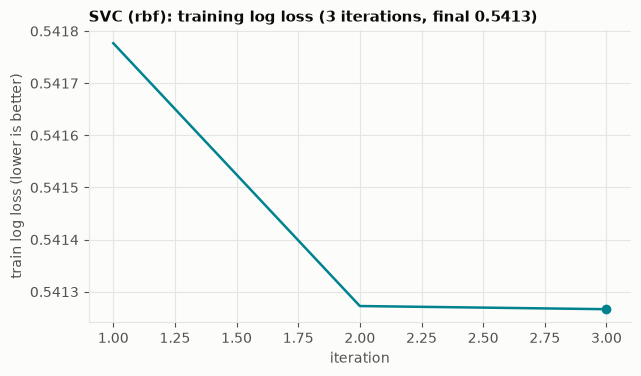

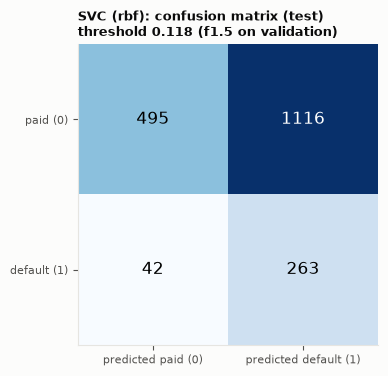

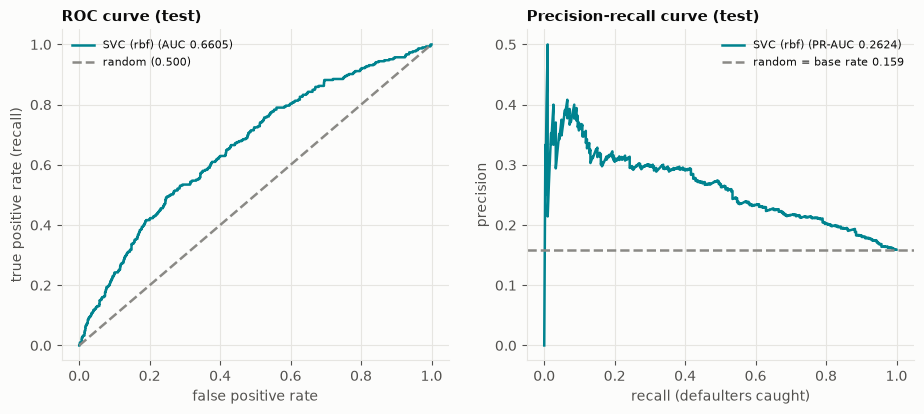

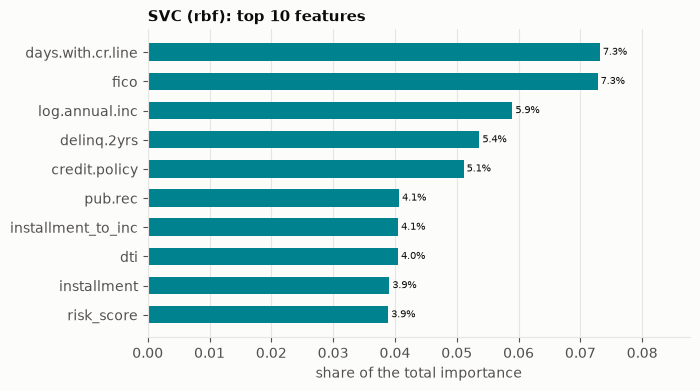


scratch vs library:
  SVC (rbf) vs sklearn SVC (rbf, balanced)
    AUC scratch 0.6605 | AUC library 0.6752 | AUC only = nan



saved + reloaded Results/Classification/07_SVC_RBF/model.joblib (identical predictions: True)


In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "SVC (rbf)", model, d, check)